Loading VGG16 model with ImageNet weights...
Loading image from: /content/drive/MyDrive/MScDS&AI/CNN/4.bird.jpg
Classifying the image...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 833ms/step

--- Top Prediction ---
goldfinch (99.99%)


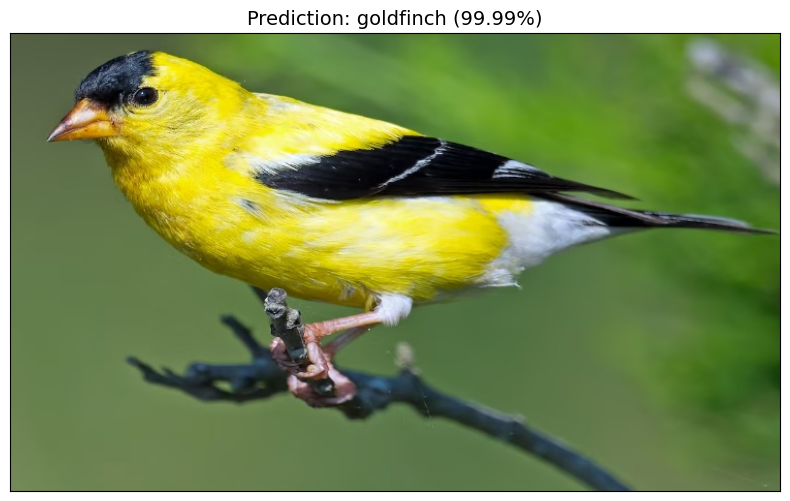

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from PIL import Image

print("Loading VGG16 model with ImageNet weights...")
# 1. Load the pre-trained VGG16 model
# The model is downloaded automatically on the first run.
model = VGG16(weights='imagenet')

# 2. Load and preprocess an input image from a local file path
image_path = '/content/drive/MyDrive/MScDS&AI/CNN/4.bird.jpg'
print(f"Loading image from: {image_path}")

# Open the image using PIL (Python Imaging Library)
original_image = Image.open(image_path).convert('RGB')

# Resize to the target size VGG16 expects (224x224)
target_size = (224, 224)
resized_image = original_image.resize(target_size)

# Convert the PIL image to a NumPy array
img_array = image.img_to_array(resized_image)

# Add a fourth dimension (batch size of 1)
img_array_expanded = np.expand_dims(img_array, axis=0)

# Preprocess the image for VGG16 (handles color channel ordering and normalization)
preprocessed_image = preprocess_input(img_array_expanded)

# 3. Make a prediction
print("Classifying the image...")
predictions = model.predict(preprocessed_image)

# 4. Decode the predictions into human-readable labels
# This function converts the model's output vector into class names
decoded_predictions = decode_predictions(predictions, top=1)[0]

# Get the single top prediction
_, label, score = decoded_predictions[0]

print("\n--- Top Prediction ---")
prediction_text = f"{label} ({score:.2%})"
print(prediction_text)

# 5. Visualize the result
plt.figure(figsize=(8, 6)) # Adjusted figure size for a simpler layout
plt.imshow(original_image)
plt.title(f"Prediction: {prediction_text}", fontsize=14)
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()